## Entrenamiento de algoritmos de clasificación

### Clasificación diagnostico


In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             cohen_kappa_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

stop_words = pd.read_excel(r"C:\Users\raultc\Documents\MAA\PROYECTO\proyecto final\stop words spanish.xlsx")
SPANISH_STOP_WORDS = set(stop_words.iloc[:, 0].str.lower().tolist())

In [2]:



df_evaluate=pd.read_excel("C:/Users/raultc/Documents/MAA/PROYECTO/proyecto final/Audit HC (2).xlsx")
df_f = df_evaluate.dropna(subset=['Motivo de consulta', 'Enfermedad actual', 'Examen Físico', 'Diagnóstico'])

In [5]:

RANDOM_STATE = 42
CRITERIO     = "Diagnóstico"     # columna del experto
N_FOLDS = 5
CV = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Tokenizador que conserva tildes y ñ
def tokenizar(texto):
    return re.findall(r"[a-záéíóúüñ]+", str(texto).lower())



df_exp = df_f.copy().reset_index(drop=True)
df_exp["caso"] = df_exp["caso"].astype(str)
df_exp["texto_sin_alterar"]  = df_exp["nota"].apply(lambda t: " ".join(tokenizar(t)))
df_exp["texto_sin_stopwords"] = df_exp["nota"].apply(
    lambda t: " ".join(w for w in tokenizar(t) if w not in SPANISH_STOP_WORDS))


y = df_exp[CRITERIO].astype(int).values
print(f"{CRITERIO}: {len(y)} notas | cumple: {(y == 1).sum()} | no cumple: {(y == 0).sum()}")

Diagnóstico: 98 notas | cumple: 81 | no cumple: 17


In [6]:
df_exp

,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico,texto_sin_alterar,texto_sin_stopwords
0,S1137-66272008000500009-1,Se presenta un caso de una paciente de 26 años...,432.0,0.432558,1.0,1.0,1.0,1.0,se presenta un caso de una paciente de años qu...,se presenta caso de paciente de años que acude...
1,S1130-05582008000400008-3,Varón de 44 años ingresado por trauma facial. ...,69.0,0.362319,1.0,0.0,0.0,1.0,varón de años ingresado por trauma facial el e...,varón de años ingresado trauma facial estudio ...
2,S1130-01082008001100009-1,Mujer de 79 años sin antecedentes de interés q...,148.0,0.412162,1.0,1.0,1.0,1.0,mujer de años sin antecedentes de interés que ...,mujer de años antecedentes de interés que cons...
3,S0212-16112008000500014-1,Varón de 78 años que ingresa en Medicina Inter...,NaN,NaN,1.0,1.0,1.0,0.0,varón de años que ingresa en medicina interna ...,varón de años que ingresa medicina interna del...
4,S1130-01082007001100010-1,Mujer de 74 años cirrótica VHC asociada a hemo...,224.0,0.384615,0.0,1.0,0.0,1.0,mujer de años cirrótica vhc asociada a hemocro...,mujer de años cirrótica vhc asociada a hemocro...
...,...,...,...,...,...,...,...,...,...,...
93,S0365-66912011001000003-1,El primer caso es el de una niña de 9 años de ...,169.0,0.534591,1.0,1.0,1.0,0.0,el primer caso es el de una niña de años de ed...,primer caso de niña de años de edad que referí...
94,S0376-78922007000300006-3,"Varón de 20 años, pescador, sin antecedentes m...",118.0,0.456140,0.0,1.0,1.0,0.0,varón de años pescador sin antecedentes médico...,varón de años pescador antecedentes médicos de...
95,S1887-85712013000200013-1,"Paciente de 3 años (94 cm, 10 Kg), niña, afgan...",167.0,0.388535,1.0,1.0,1.0,0.0,paciente de años cm kg niña afgana con signos ...,paciente de años cm kg niña afgana signos de d...
96,S0212-71992006000900007-1,Varón de 51 años que acudió a las consultas de...,337.0,0.455357,1.0,1.0,1.0,1.0,varón de años que acudió a las consultas de de...,varón de años que acudió a consultas de dermat...


### Representaciones

- **BoW**: conteo de palabras.
- **TF-IDF**: conteo ponderado por lo rara que es cada palabra en el corpus.
- **W2V**: promedio de los vectores Word2Vec de las palabras de la nota.
- **W2V + TF-IDF**: promedio de los vectores Word2Vec ponderado por el peso TF-IDF de cada palabra.

Todas van dentro de un pipeline, así que en cada fold se entrenan **solo con las notas de train**

Notas del experto: 98 | cumple: 81 | no cumple: 17
✓ Sin números – BoW
✓ Sin números – TF-IDF
✓ Sin números – W2V
✓ Sin números – W2V + TF-IDF
✓ Con números – BoW
✓ Con números – TF-IDF
✓ Con números – W2V
✓ Con números – W2V + TF-IDF
✓ Número genérico – BoW
✓ Número genérico – TF-IDF
✓ Número genérico – W2V
✓ Número genérico – W2V + TF-IDF


F1_media  F1_desv  Recall_No_cumple  Acc_media
Tokenización    Representación                                                
Número genérico W2V + TF-IDF       0.610    0.216             0.233      0.868
Con números     W2V + TF-IDF       0.593    0.138             0.300      0.837
                TF-IDF             0.589    0.186             0.300      0.847
Sin números     BoW                0.583    0.205             0.250      0.848
Con números     BoW                0.583    0.205             0.250      0.848
Número genérico BoW                0.583    0.205             0.250      0.848
Sin números     TF-IDF             0.569    0.164             0.300      0.826
Número genérico TF-IDF             0.560    0.157             0.300      0.815
Sin números     W2V + TF-IDF       0.540    0.118             0.250      0.816
                W2V                0.521    0.128             0.183      0.747
Número genérico W2V                0.451    0.033             0.050      0.757
Con números     W2V                0.401    0.164             0.267      0.626

Tokenización,Sin números,Con números,Número genérico
Representación,,,
BoW,0.583 ± 0.205,0.583 ± 0.205,0.583 ± 0.205
TF-IDF,0.569 ± 0.164,0.589 ± 0.186,0.560 ± 0.157
W2V,0.521 ± 0.128,0.401 ± 0.164,0.451 ± 0.033
W2V + TF-IDF,0.540 ± 0.118,0.593 ± 0.138,0.610 ± 0.216


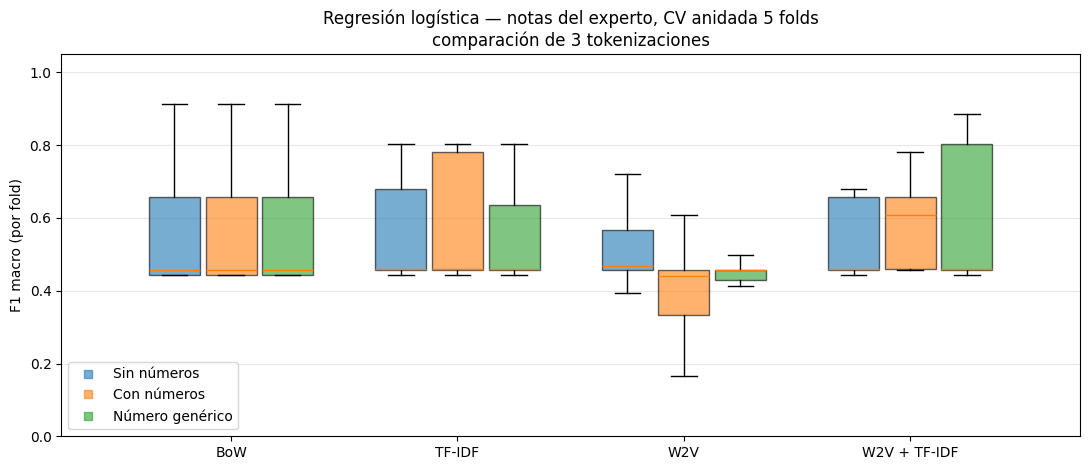

In [8]:
# =====================================================================
# CLASIFICACIÓN — ¿Qué tokenización clasifica mejor?
# Notas del EXPERTO (df_exp) · Regresión logística (elastic net)
# Validación cruzada anidada, igual que la celda 10:
#   CV externo = 5 folds (mide F1) | CV interno = 3 folds (elige C y l1_ratio)
# 3 tokenizaciones × 4 representaciones
# =====================================================================
import re, unicodedata, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, recall_score, accuracy_score
from sklearn.exceptions import ConvergenceWarning

RANDOM_STATE = 42

# 1) Datos: notas y etiquetas del experto
datos = df_exp[df_exp["Diagnóstico"].notna()].reset_index(drop=True)
y_exp = datos["Diagnóstico"].astype(int).to_numpy()
print(f"Notas del experto: {len(y_exp)} | cumple: {(y_exp == 1).sum()} | no cumple: {(y_exp == 0).sum()}")

# 2) Las 3 tokenizaciones -> 3 columnas de texto
def _normalizar(texto):
    return unicodedata.normalize("NFC", str(texto)).lower()

def tok_sin_numeros(texto):
    return re.findall(r"[a-záéíóúüñ]+", _normalizar(texto))

def tok_con_numeros(texto):
    return re.findall(r"[a-záéíóúüñ]+|\d+", _normalizar(texto))

def tok_num_generico(texto):
    return re.findall(r"[a-záéíóúüñ]+", re.sub(r"\d+", " num ", _normalizar(texto)))

TOKENIZACIONES = {"Sin números": tok_sin_numeros,
                  "Con números": tok_con_numeros,
                  "Número genérico": tok_num_generico}

TEXTOS_TOK = {}
for nombre_tok, tok in TOKENIZACIONES.items():
    TEXTOS_TOK[nombre_tok] = datos["nota"].fillna("").apply(lambda t: " ".join(tok(t)))

# 3) Representaciones (misma configuración que REPRESENTACIONES).
#    W2V con su propio .split(): no depende de la función global `tokenizar`.
class W2VClf(BaseEstimator, TransformerMixin):
    def __init__(self, vector_size=100, window=5, min_count=2, seed=42):
        self.vector_size, self.window = vector_size, window
        self.min_count, self.seed = min_count, seed

    def fit(self, X, y=None):
        self.w2v_ = Word2Vec([str(t).split() for t in X], vector_size=self.vector_size,
                             window=self.window, min_count=self.min_count,
                             seed=self.seed, workers=1)
        return self

    def transform(self, X):
        filas = []
        for t in X:
            vecs = [self.w2v_.wv[p] for p in str(t).split() if p in self.w2v_.wv]
            filas.append(np.mean(vecs, axis=0) if vecs else np.zeros(self.vector_size))
        return np.vstack(filas)

REPS_CLF = {
    "BoW":          lambda: CountVectorizer(min_df=2),
    "TF-IDF":       lambda: TfidfVectorizer(ngram_range=(1, 3), min_df=3),
    "W2V":          lambda: W2VClf(),
    "W2V + TF-IDF": lambda: FeatureUnion([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 3), min_df=3)),
        ("w2v",   W2VClf()),
    ]),
}

# 4) Regresión logística + búsqueda de hiperparámetros (igual que la celda 10)
GRILLA = {
    "clf__C": np.logspace(-3, 2, 11),
    "clf__l1_ratio": [0.0, 0.5, 1.0],     # 0 = L2, 1 = L1
}

def pipeline_logistica(nombre_rep):
    densa = nombre_rep == "W2V"
    return Pipeline([
        ("rep", REPS_CLF[nombre_rep]()),
        ("esc", StandardScaler() if densa else MaxAbsScaler()),
        ("clf", LogisticRegression(solver="saga", penalty="elasticnet", tol=1e-4,
                                   class_weight="balanced", max_iter=5000,
                                   random_state=RANDOM_STATE)),
    ])

cv_externo = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_interno = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# 5) Validación cruzada anidada: 3 tokenizaciones × 4 representaciones
#    (los mismos folds para todas, así la comparación es justa)
folds = list(cv_externo.split(datos, y_exp))
filas_clf, pred_tok = [], {}

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    warnings.simplefilter("ignore", FutureWarning)
    for nombre_tok, textos in TEXTOS_TOK.items():
        for nombre_rep in REPS_CLF:
            pred_oof = np.empty(len(y_exp), dtype=int)
            for i, (tr, te) in enumerate(folds):
                busqueda = GridSearchCV(pipeline_logistica(nombre_rep), GRILLA,
                                        scoring="f1_macro", cv=cv_interno, n_jobs=-1)
                busqueda.fit(textos.iloc[tr], y_exp[tr])
                y_pred = busqueda.predict(textos.iloc[te])
                pred_oof[te] = y_pred
                filas_clf.append({
                    "Tokenización": nombre_tok,
                    "Representación": nombre_rep,
                    "Fold": i,
                    "F1 macro": f1_score(y_exp[te], y_pred, average="macro"),
                    "Recall No cumple": recall_score(y_exp[te], y_pred, pos_label=0),
                    "Accuracy": accuracy_score(y_exp[te], y_pred),
                    "C": busqueda.best_params_["clf__C"],
                    "l1_ratio": busqueda.best_params_["clf__l1_ratio"],
                })
            pred_tok[(nombre_tok, nombre_rep)] = pred_oof
            print(f"✓ {nombre_tok} – {nombre_rep}")

df_folds_tok = pd.DataFrame(filas_clf)

# 6) Resultados
resumen_tok = (df_folds_tok
    .groupby(["Tokenización", "Representación"], sort=False)
    .agg(F1_media=("F1 macro", "mean"), F1_desv=("F1 macro", "std"),
         Recall_No_cumple=("Recall No cumple", "mean"), Acc_media=("Accuracy", "mean"))
    .sort_values("F1_media", ascending=False)
    .round(3))
display(resumen_tok)

# Tabla compacta: F1 macro (media ± desv) por representación y tokenización
tabla_f1 = (df_folds_tok.groupby(["Representación", "Tokenización"], sort=False)["F1 macro"]
            .agg(lambda s: f"{s.mean():.3f} ± {s.std():.3f}")
            .unstack()[list(TOKENIZACIONES)])
display(tabla_f1)

# Boxplot del F1 por fold
fig, ax = plt.subplots(figsize=(11, 4.8))
reps = list(REPS_CLF)
ancho = 0.25
for k, nombre_tok in enumerate(TOKENIZACIONES):
    datos_box = [df_folds_tok.query("Tokenización == @nombre_tok and Representación == @r")["F1 macro"]
                 for r in reps]
    pos = np.arange(len(reps)) + (k - 1) * ancho
    bp = ax.boxplot(datos_box, positions=pos, widths=ancho * 0.9, patch_artist=True)
    for caja in bp["boxes"]:
        caja.set_facecolor(f"C{k}"); caja.set_alpha(0.6)
    ax.plot([], [], "s", color=f"C{k}", alpha=0.6, label=nombre_tok)
ax.set_xticks(np.arange(len(reps))); ax.set_xticklabels(reps)
ax.set(ylabel="F1 macro (por fold)", ylim=(0, 1.05),
       title="Regresión logística — notas del experto, CV anidada 5 folds\n"
             "comparación de 3 tokenizaciones")
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("f1_tokenizaciones_logistica.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
import numpy as np
from gensim.models import Word2Vec
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import FeatureUnion

def tokenizar(texto):
    return str(texto).lower().split()

class W2VPromedio(BaseEstimator, TransformerMixin):
    """Entrena Word2Vec con los textos de train y representa cada nota
    como el promedio de los vectores de sus palabras."""
    def __init__(self, vector_size=100, window=5, min_count=2, seed=42):
        self.vector_size = vector_size
        self.window = window
        self.min_count = min_count
        self.seed = seed

    def fit(self, X, y=None):
        frases = [tokenizar(t) for t in X]
        self.w2v_ = Word2Vec(frases, vector_size=self.vector_size, window=self.window,
                             min_count=self.min_count, seed=self.seed, workers=1)
        return self

    def transform(self, X):
        filas = []
        for t in X:
            vecs = [self.w2v_.wv[p] for p in tokenizar(t) if p in self.w2v_.wv]
            filas.append(np.mean(vecs, axis=0) if vecs else np.zeros(self.vector_size))
        return np.vstack(filas)

REPRESENTACIONES = {
    "BoW":        lambda: CountVectorizer(min_df=2),
    "TF-IDF":     lambda: TfidfVectorizer(ngram_range=(1, 3), min_df=3),
    "W2V":        lambda: W2VPromedio(),
    "W2V + TF-IDF": lambda: FeatureUnion([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 3), min_df=3)),
        ("w2v",   W2VPromedio()),
    ]),
}

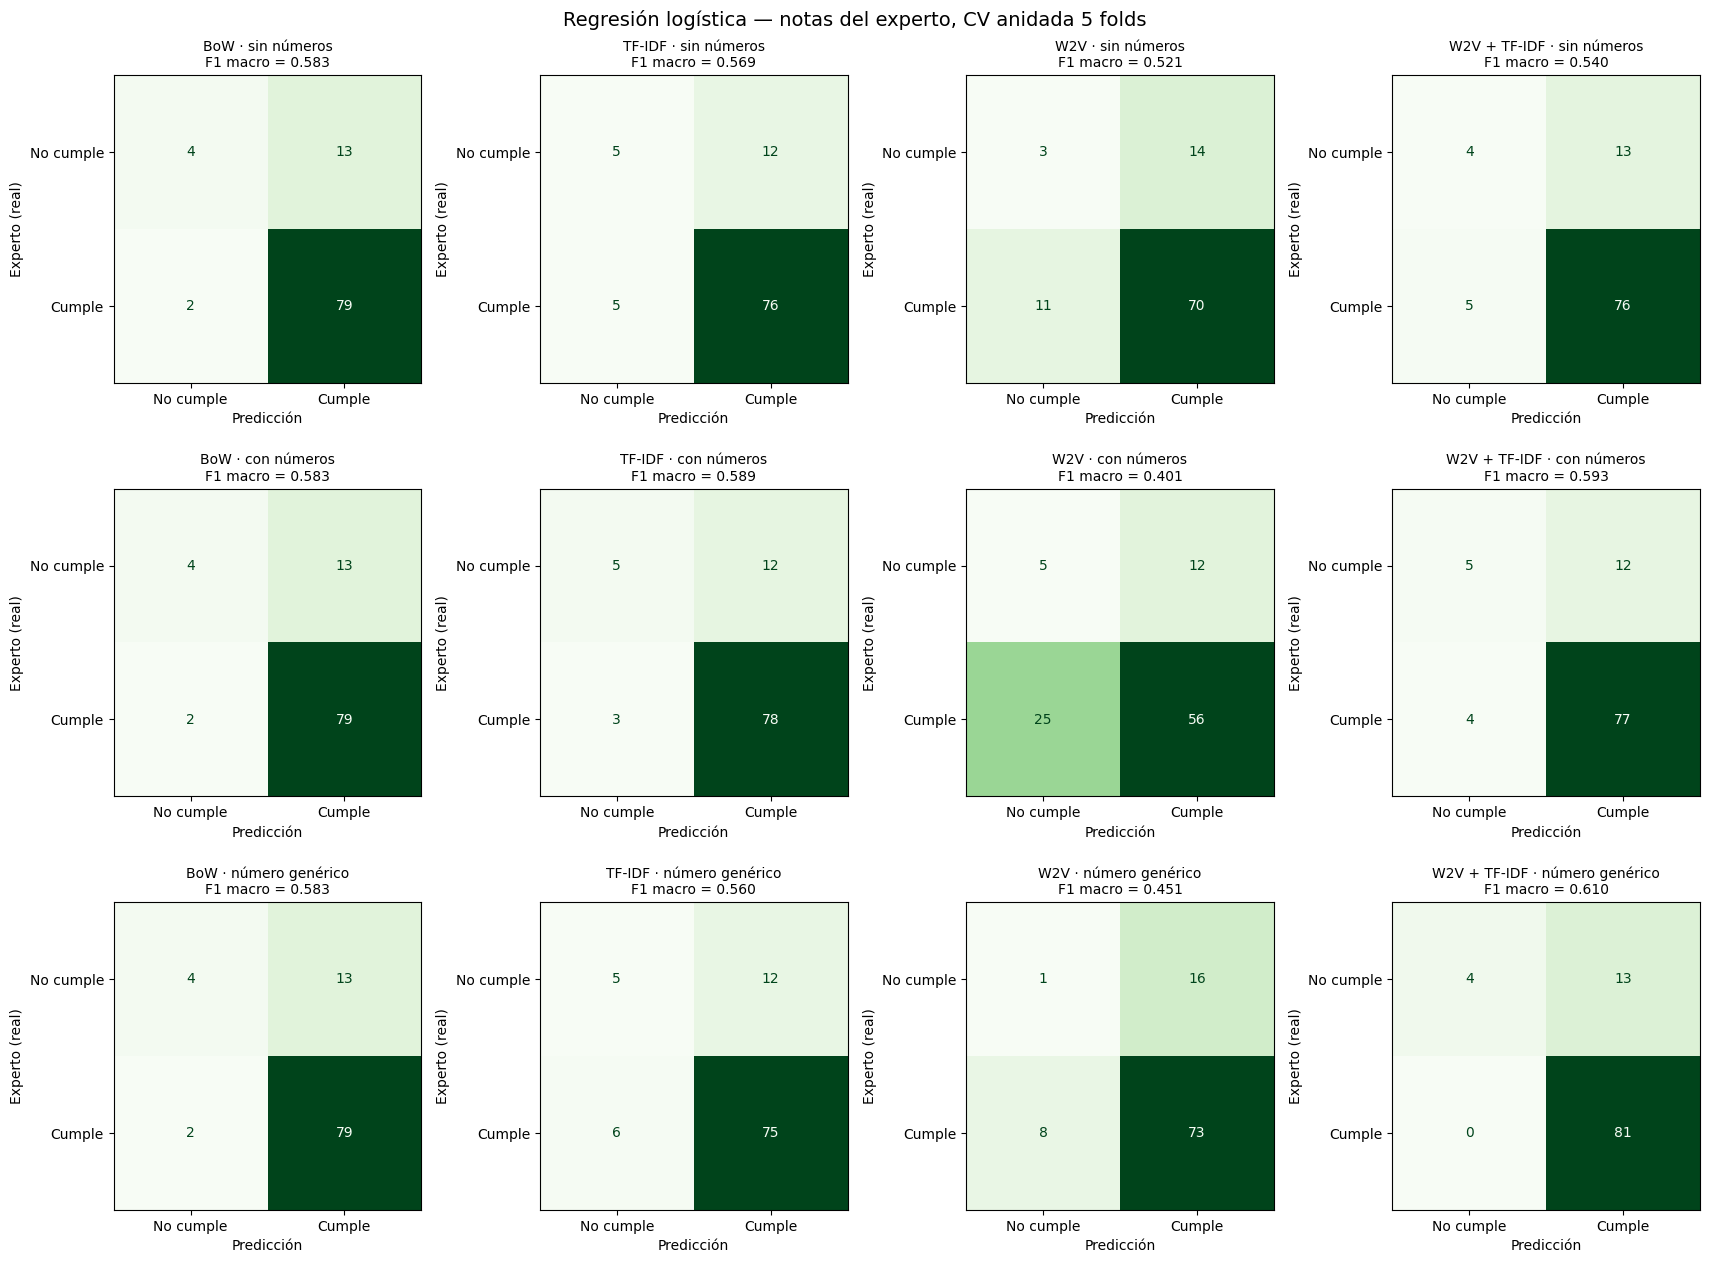

In [10]:
# =====================================================================
# Matrices de confusión — 3 tokenizaciones × 4 representaciones
# Predicciones out-of-fold de la CV anidada (cada nota se predice una vez,
# cuando estaba en el fold de test)
# =====================================================================
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

n_filas, n_cols = len(TOKENIZACIONES), len(REPS_CLF)
fig, axes = plt.subplots(n_filas, n_cols, figsize=(4.3 * n_cols, 4.3 * n_filas), squeeze=False)

for fila_ax, nombre_tok in zip(axes, TOKENIZACIONES):
    for ax, nombre_rep in zip(fila_ax, REPS_CLF):
        cm = confusion_matrix(y_exp, pred_tok[(nombre_tok, nombre_rep)], labels=[0, 1])
        f1 = resumen_tok.loc[(nombre_tok, nombre_rep), "F1_media"]
        ConfusionMatrixDisplay(cm, display_labels=["No cumple", "Cumple"]).plot(
            ax=ax, cmap="Greens", colorbar=False, values_format="d")
        ax.set_title(f"{nombre_rep} · {nombre_tok.lower()}\nF1 macro = {f1:.3f}", fontsize=10)
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Experto (real)")

plt.suptitle("Regresión logística — notas del experto, CV anidada 5 folds", fontsize=14)
plt.tight_layout()
plt.savefig("matrices_confusion_tokenizaciones.png", dpi=200, bbox_inches="tight")
plt.show()

Se elige tf-idf con numeros ya que clasifica un poco mejor los no cumplen

In [11]:
# =====================================================================
# CELDA 1 — Revisar la dimensión de los vectores de cada representación
# Pégala después de la celda donde defines REPRESENTACIONES y clasificador().
# Mide los vectores DENTRO de cada fold (solo con las notas de train),
# que es exactamente lo que recibe la regresión logística.
# =====================================================================
from scipy import sparse
from collections import Counter

TEXTOS = {"Con stopwords": "texto_sin_alterar", "sin stopwords": "texto_sin_stopwords"}

def medir_vectores(rep, textos):
    """Ajusta la representación y devuelve (n_notas, n_dimensiones, densidad, activas_por_nota)."""
    X = rep.fit_transform(textos)
    n, d = X.shape
    if sparse.issparse(X):
        densidad = X.nnz / (n * d)
        activas = X.getnnz(axis=1).mean()
    else:
        densidad = np.count_nonzero(X) / X.size
        activas = np.count_nonzero(X, axis=1).mean()
    return n, d, densidad, activas

filas_dim = []
for nombre_texto, col_texto in TEXTOS.items():
    for nombre_rep, crear_rep in REPRESENTACIONES.items():
        res = np.array([medir_vectores(crear_rep(), df_exp[col_texto].iloc[tr])
                        for tr, _ in CV.split(df_exp[col_texto], y)])
        n_train, dims = res[:, 0].mean(), res[:, 1]
        filas_dim.append({
            "Texto": nombre_texto,
            "Representación": nombre_rep,
            "Notas train (por fold)": int(n_train),
            "Dimensiones (media)": int(dims.mean()),
            "Dim. mín–máx entre folds": f"{int(dims.min())}–{int(dims.max())}",
            "Dimensiones / notas": round(dims.mean() / n_train, 1),
            "% celdas ≠ 0": round(res[:, 2].mean() * 100, 1),
            "Dimensiones activas por nota": int(res[:, 3].mean()),
        })

df_dim = pd.DataFrame(filas_dim)
display(df_dim)

# Contexto: cuántas notas hay por clase en train (la clase minoritaria es la que limita)
n_min = int((y == 0).sum() * (N_FOLDS - 1) / N_FOLDS)
print(f"Clase minoritaria ('No cumple') en train por fold: ~{n_min} notas")



,Texto,Representación,Notas train (por fold),Dimensiones (media),Dim. mín–máx entre folds,Dimensiones / notas,% celdas ≠ 0,Dimensiones activas por nota
0,Con stopwords,BoW,78,2078,2039–2131,26.5,7.0,146
1,Con stopwords,TF-IDF,78,2697,2635–2774,34.4,8.4,227
2,Con stopwords,W2V,78,100,100–100,1.3,100.0,100
3,Con stopwords,W2V + TF-IDF,78,2797,2735–2874,35.7,11.7,327
4,sin stopwords,BoW,78,2006,1968–2060,25.6,6.4,127
5,sin stopwords,TF-IDF,78,1992,1961–2054,25.4,8.1,160
6,sin stopwords,W2V,78,100,100–100,1.3,100.0,100
7,sin stopwords,W2V + TF-IDF,78,2092,2061–2154,26.7,12.5,260


Clase minoritaria ('No cumple') en train por fold: ~13 notas


#### Los numeros pierden información??


- Elegir el clasificador

In [12]:
from functools import partial
from sklearn.linear_model import LogisticRegression

clasificador = partial(
    LogisticRegression,
    tol=1e-4,                 # saga converge lento con BoW/TF-IDF
    class_weight="balanced",   # compensa el desbalance (~14 "No cumple" por fold)
    max_iter=5000,             # saga converge lento, sobre todo con BoW/TF-IDF
    random_state=RANDOM_STATE,
)

In [13]:
# =====================================================================
# CELDA 2 — Parametrizar la regresión logística por representación
# Validación cruzada anidada: CV externo = tu CV; CV interno = búsqueda de C y l1_ratio
# =====================================================================
from tempfile import mkdtemp
from shutil import rmtree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, recall_score, accuracy_score

GRILLA = {
    "clf__C": np.logspace(-3, 2, 11),
    "clf__l1_ratio": [0.0, 0.5, 1.0],   # 0 = L2, 1 = L1
}

def construir_pipeline(nombre_rep, crear_rep, cache):
    densa = nombre_rep == "W2V"
    return Pipeline([
        ("rep", crear_rep()),
        ("esc", StandardScaler() if densa else MaxAbsScaler()),
        ("clf", clasificador(solver="saga", penalty="elasticnet")),
    ], memory=cache)

y = np.asarray(y)
cv_interno = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cache = mkdtemp()

filas, predicciones = [], {}
for nombre_texto, col_texto in TEXTOS.items():
    textos = df_exp[col_texto]
    for nombre_rep, crear_rep in REPRESENTACIONES.items():
        pred_oof = np.empty(len(y), dtype=int)
        for i, (tr, te) in enumerate(CV.split(textos, y)):
            busqueda = GridSearchCV(
                construir_pipeline(nombre_rep, crear_rep, cache), GRILLA,
                scoring="f1_macro", cv=cv_interno, n_jobs=1,
            )
            busqueda.fit(textos.iloc[tr], y[tr])
            y_pred = busqueda.predict(textos.iloc[te])
            pred_oof[te] = y_pred
            filas.append({
                "Texto": nombre_texto,
                "Representación": nombre_rep,
                "Fold": i,
                "F1 macro test": f1_score(y[te], y_pred, average="macro"),
                "Recall test": recall_score(y[te], y_pred),      # recall de "Cumple" (1)
                "Accuracy test": accuracy_score(y[te], y_pred),
            })
        predicciones[(nombre_texto, nombre_rep)] = pred_oof
        print(f"✓ {nombre_texto} – {nombre_rep}")

rmtree(cache)
df_folds = pd.DataFrame(filas)

resumen = (df_folds
    .groupby(["Texto", "Representación"], sort=False)
    .agg(F1_media=("F1 macro test", "mean"),
         Recall_Cumple=("Recall test", "mean"),
         Acc_media=("Accuracy test", "mean"),
    )
    .sort_values("F1_media", ascending=False)
    .round(3))
display(resumen)

c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\sit

✓ Con stopwords – BoW


c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\sit

✓ Con stopwords – TF-IDF


c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\sit

✓ Con stopwords – W2V


... (7 outputs left out)

✓ sin stopwords – W2V


c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\biacus\.conda\envs\clinicaus\lib\sit

✓ sin stopwords – W2V + TF-IDF


F1_media  Recall_Cumple  Acc_media
Texto         Representación                                    
sin stopwords W2V + TF-IDF       0.605          0.913      0.817
Con stopwords BoW                0.583          0.976      0.848
              TF-IDF             0.569          0.938      0.826
sin stopwords BoW                0.559          0.951      0.827
Con stopwords W2V + TF-IDF       0.540          0.938      0.816
sin stopwords TF-IDF             0.537          0.951      0.816
Con stopwords W2V                0.521          0.867      0.747
sin stopwords W2V                0.490          0.890      0.756

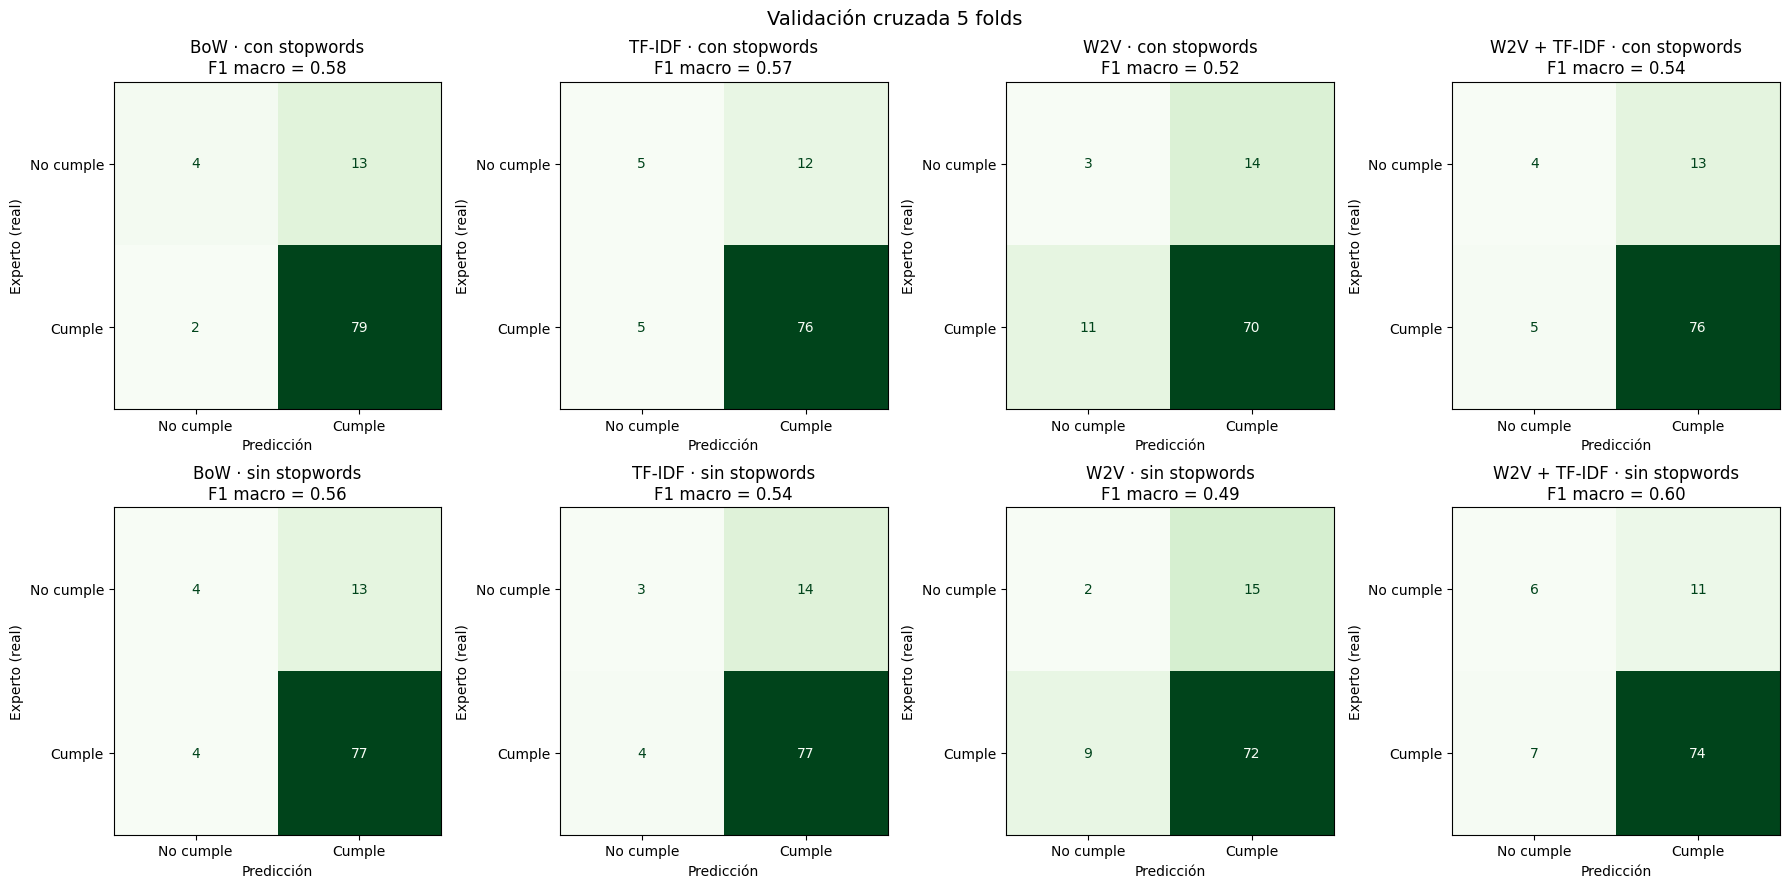

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

n_filas, n_cols = len(TEXTOS), len(REPRESENTACIONES)
fig, axes = plt.subplots(n_filas, n_cols, figsize=(4.5 * n_cols, 4.5 * n_filas), squeeze=False)

for fila_ax, nombre_texto in zip(axes, TEXTOS):
    for ax, nombre_rep in zip(fila_ax, REPRESENTACIONES):
        cm = confusion_matrix(y, predicciones[(nombre_texto, nombre_rep)], labels=[0, 1])
        f1 = resumen.loc[(nombre_texto, nombre_rep), "F1_media"]
        ConfusionMatrixDisplay(cm, display_labels=["No cumple", "Cumple"]).plot(
            ax=ax, cmap="Greens", colorbar=False, values_format="d")
        ax.set_title(f"{nombre_rep} · {nombre_texto.lower()}\nF1 macro = {f1:.2f}")
        ax.set_xlabel("Predicción")
        ax.set_ylabel("Experto (real)")

plt.suptitle(f"Validación cruzada {CV.get_n_splits()} folds", fontsize=14)
plt.tight_layout()
plt.show()

## Entrenamiento del mejor modelo

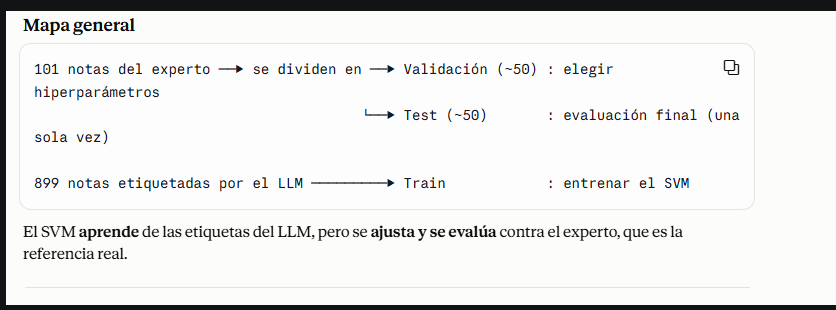

### Experimentos 


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import (f1_score, recall_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

CRIT = "Diagnóstico"

In [16]:
df_exp = pd.read_excel(r"C:\Users\raultc\Documents\MAA\PROYECTO\proyecto final\Audit HC (2).xlsx", sheet_name="Sheet1")
df_exp["caso"] = df_exp["caso"].astype(str)

In [17]:
df_exp

,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico
0,S1137-66272008000500009-1,Se presenta un caso de una paciente de 26 años...,432.0,0.432558,1.0,1.0,1.0,1.0
1,S1130-05582008000400008-3,Varón de 44 años ingresado por trauma facial. ...,69.0,0.362319,1.0,0.0,0.0,1.0
2,S1130-01082008001100009-1,Mujer de 79 años sin antecedentes de interés q...,148.0,0.412162,1.0,1.0,1.0,1.0
3,S0212-16112008000500014-1,Varón de 78 años que ingresa en Medicina Inter...,NaN,NaN,1.0,1.0,1.0,0.0
4,S1130-01082007001100010-1,Mujer de 74 años cirrótica VHC asociada a hemo...,224.0,0.384615,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...
992,S1130-01082009000700016-1,Presentamos el caso de un paciente de 77 años ...,251.0,0.483607,NaN,NaN,NaN,NaN
993,S0210-48062009000300013-3,Varón de 74 años\nAntecedentes personales: HTA...,146.0,0.355072,NaN,NaN,NaN,NaN
994,S0004-06142006000900009-1,Paciente de 26 años que es remitido desde las ...,269.0,0.470149,NaN,NaN,NaN,NaN
995,S1130-01082005001100016-1,Mujer de 59 años sin antecedentes de interés q...,281.0,0.418251,NaN,NaN,NaN,NaN


In [18]:
COL_EXP = "Diagnóstico"

# Si alguna nota se usó como ejemplo few-shot, se excluye de la evaluación
IDS_EJEMPLOS = set()          # p. ej. {"12", "45"}
df_exp = df_exp[~df_exp["caso"].isin(IDS_EJEMPLOS)]
df_exp = df_exp[df_exp[COL_EXP].notna()]

print("Notas del experto:", len(df_exp))
print(df_exp[COL_EXP].value_counts())

Notas del experto: 98
Diagnóstico
1.0    81
0.0    17
Name: count, dtype: int64


### Dividir las notas del experto en validación y test

In [ ]:
df_val, df_test = train_test_split(
    df_exp,
    test_size=0.5,
    stratify=df_exp[COL_EXP],
    random_state=42,
)

print("Validación:", df_val[COL_EXP].value_counts().to_dict())
print("Test:      ", df_test[COL_EXP].value_counts().to_dict())

# Guarda la división para que siempre sea la misma
df_val[["caso"]].to_csv("ids_validacion_diagnostico.csv", index=False)
df_test[["caso"]].to_csv("ids_test_diagnostico.csv", index=False)

Validación: {1.0: 41, 0.0: 8}
Test:       {1.0: 40, 0.0: 9}


### Cargar las 899 notas etiquetadas por el LLM

utilizare 899 train que salieron del LLM para el val y test se usaran 98 del experto

In [24]:
df_fewshot = pd.read_csv(r"C:\Users\raultc\Documents\MAA\PROYECTO\proyecto final\criterios_auditoria_fewshot_por_criterio.csv")

In [25]:
df_fewshot

,caso,motivo_consulta,motivo_consulta_razon,enfermedad_actual,enfermedad_actual_razon,examen_fisico,examen_fisico_razon,diagnostico,diagnostico_razon
0,S1137-66272008000500009-1,1,La paciente acude a consulta específicamente p...,1,Se describe un cuadro clínico con dolor en la ...,1,Se reportan hallazgos de la exploración física...,1,Se establece un diagnóstico claro de condrobla...
1,S1130-05582008000400008-3,1,"El ingreso se menciona por trauma facial, lo q...",0,El caso describe un evento aislado de trauma f...,0,No se reportan hallazgos de la exploración fís...,1,Se establece un diagnóstico claro de quiste ra...
2,S1130-01082008001100009-1,1,La paciente consultó específicamente por diarr...,1,Se describe un cuadro clínico en evolución con...,1,Se reporta una exploración física que incluye ...,1,Se establece claramente el diagnóstico de hepa...
3,S0212-16112008000500014-1,1,El paciente ingresa refiriendo aumento en el n...,1,Se describe un cuadro clínico en evolución con...,1,Se reportan hallazgos de la exploración física...,1,Se establece un diagnóstico de infección por C...
4,S1130-01082007001100010-1,0,El texto describe la condición y el tratamient...,1,Se describe un cuadro clínico en evolución con...,1,Se reportan hallazgos de la ecografía abdomina...,0,Se menciona el diagnóstico de encefalopatía he...
...,...,...,...,...,...,...,...,...,...
992,S1130-01082009000700016-1,1,El paciente acudió para la realización de una ...,1,Se describe un cuadro clínico en evolución: mo...,0,No se reportan hallazgos de la exploración fís...,0,No se establece un diagnóstico específico en e...
993,S0210-48062009000300013-3,0,El texto describe el estado del paciente y sus...,1,Describe el desarrollo del cuadro clínico desd...,0,No se reporta una exploración física externa d...,0,No se establece un diagnóstico claro en las no...
994,S0004-06142006000900009-1,1,El paciente es remitido para valorar lesiones ...,1,Se describe la evolución de la enfermedad de C...,0,El caso clínico se centra en la historia médic...,1,Se establece el diagnóstico de granuloma no ca...
995,S1130-01082005001100016-1,1,El ingreso de la paciente se debe a dolor en e...,1,Se describe un cuadro clínico con síntomas com...,1,Se reportan hallazgos de la exploración física...,1,Se establece el diagnóstico de quiste hidatídi...


In [26]:
df_fewshot["diagnostico_few"] = df_fewshot["diagnostico"]

In [27]:
df_notas = df_evaluate.copy()
df_notas["caso"] = df_notas["caso"].astype(str)

df_notas = df_notas[["caso", "nota"]]

df_llm = df_fewshot                  
df_llm["caso_fewshot"] = df_llm["caso"].astype(str)

df_llm=df_llm[["caso_fewshot", "diagnostico_few"]]

In [28]:
df_llm_f = df_notas.merge(
    df_llm[["caso_fewshot", "diagnostico_few"]],
    left_on="caso",
    right_on="caso_fewshot",
    how="left"
).drop(columns="caso_fewshot")

In [29]:
df_train = df_llm_f[~df_llm_f["caso"].isin(df_exp["caso"])]


# Seguridad: ninguna nota de validación o test puede estar en train
df_train = df_train[~df_train["caso"].isin(df_exp["caso"])]

print("Train:", len(df_train))
print(len(df_train))  # debería dar 997 - 98 = 899

Train: 899
899


In [30]:
df_train

,caso,nota,diagnostico_few
98,S1139-76322009000700014-2,Paciente de 14 años que acude a la consulta po...,1
99,S0213-12852005000400003-1,"Paciente varón, de 47 años, casado, acude al d...",1
100,S0212-71992000001200006-1,"Varón de 49 años, peruano con 10 años de resid...",1
101,S1130-14732009000300006-1,Una mujer de 26 años sin antecedentes neurológ...,1
102,S0365-66912009000100008-1,Paciente varón de 28 años de edad que sufre un...,1
...,...,...,...
992,S1130-01082009000700016-1,Presentamos el caso de un paciente de 77 años ...,0
993,S0210-48062009000300013-3,Varón de 74 años\nAntecedentes personales: HTA...,0
994,S0004-06142006000900009-1,Paciente de 26 años que es remitido desde las ...,1
995,S1130-01082005001100016-1,Mujer de 59 años sin antecedentes de interés q...,1


In [31]:
### Ganardor tokenización: tf-idf + con stopwords + con números
## Se eligen porque eligen mejor los que no cumplen

def _normalizar(texto):
    return unicodedata.normalize("NFC", str(texto)).lower()

def tok_con_numeros(texto):
    return re.findall(r"[a-záéíóúüñ]+|\d+", _normalizar(texto))

df_train["Texto_g"]  = df_train["nota"].apply(lambda t: " ".join(tok_con_numeros(t)))


In [32]:
df_train

,caso,nota,diagnostico_few,Texto_g
98,S1139-76322009000700014-2,Paciente de 14 años que acude a la consulta po...,1,paciente de 14 años que acude a la consulta po...
99,S0213-12852005000400003-1,"Paciente varón, de 47 años, casado, acude al d...",1,paciente varón de 47 años casado acude al depa...
100,S0212-71992000001200006-1,"Varón de 49 años, peruano con 10 años de resid...",1,varón de 49 años peruano con 10 años de reside...
101,S1130-14732009000300006-1,Una mujer de 26 años sin antecedentes neurológ...,1,una mujer de 26 años sin antecedentes neurológ...
102,S0365-66912009000100008-1,Paciente varón de 28 años de edad que sufre un...,1,paciente varón de 28 años de edad que sufre un...
...,...,...,...,...
992,S1130-01082009000700016-1,Presentamos el caso de un paciente de 77 años ...,0,presentamos el caso de un paciente de 77 años ...
993,S0210-48062009000300013-3,Varón de 74 años\nAntecedentes personales: HTA...,0,varón de 74 años antecedentes personales hta e...
994,S0004-06142006000900009-1,Paciente de 26 años que es remitido desde las ...,1,paciente de 26 años que es remitido desde las ...
995,S1130-01082005001100016-1,Mujer de 59 años sin antecedentes de interés q...,1,mujer de 59 años sin antecedentes de interés q...


In [33]:
df_val["Texto_g"]  = df_val["nota"].apply(lambda t: " ".join(tok_con_numeros(t)))
df_val


,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico,Texto_g
0,S1137-66272008000500009-1,Se presenta un caso de una paciente de 26 años...,432.0,0.432558,1.0,1.0,1.0,1.0,se presenta un caso de una paciente de 26 años...
52,S0212-16112010000600022-1,Paciente de 65 años de edad con antecedentes p...,829.0,0.423126,1.0,1.0,1.0,1.0,paciente de 65 años de edad con antecedentes p...
80,S1139-76322012000400011-1,Presentamos el caso de un varón de 11 años ori...,163.0,0.487500,1.0,1.0,1.0,1.0,presentamos el caso de un varón de 11 años ori...
55,S1139-76322014000500014-1,Niño de cinco años derivado por su pediatra de...,280.0,0.440000,1.0,1.0,1.0,0.0,niño de cinco años derivado por su pediatra de...
91,S0365-66912010000700004-1,Mujer de 61 años con antecedentes sistémicos d...,222.0,0.454976,1.0,1.0,1.0,0.0,mujer de 61 años con antecedentes sistémicos d...
33,S1130-01082008001000008-1,Varón de 61 años con antecedente de DMNID que ...,150.0,0.424658,1.0,0.0,0.0,1.0,varón de 61 años con antecedente de dmnid que ...
34,S1699-695X2014000200007-1,"Se trata de un varón de 22 años, asténico, álg...",401.0,0.461929,1.0,1.0,1.0,1.0,se trata de un varón de 22 años asténico álgid...
54,S1698-69462006000100019-1,Varón de 62 años diagnosticado en septiembre d...,260.0,0.404000,1.0,1.0,1.0,1.0,varón de 62 años diagnosticado en septiembre d...
82,S0004-06142006000900014-1,"Paciente mujer de 81 años de edad, se presenta...",423.0,0.382212,1.0,1.0,1.0,1.0,paciente mujer de 81 años de edad se presenta ...
8,S0365-66912011000600005-2,Varón de 37 años ex-adicto a drogas por vía pa...,133.0,0.448819,1.0,1.0,1.0,1.0,varón de 37 años ex adicto a drogas por vía pa...


In [35]:
df_test["Texto_g"]  = df_test["nota"].apply(lambda t: " ".join(tok_con_numeros(t)))

df_test

,caso,nota,num_words,stopword_ratio,Motivo de consulta,Enfermedad actual,Examen Físico,Diagnóstico,Texto_g
35,S2340-98942015000100005-1,Presentamos el caso de una paciente de 62 años...,304.0,0.472028,0.0,1.0,0.0,1.0,presentamos el caso de una paciente de 62 años...
14,S1130-01082007000500016-1,"Se trata de un paciente varón de 72 años, con ...",354.0,0.377522,1.0,1.0,1.0,1.0,se trata de un paciente varón de 72 años con a...
9,S1130-01082007000300014-1,"Varón de 65 años, sin antecedentes de interés,...",238.0,0.403433,1.0,1.0,1.0,1.0,varón de 65 años sin antecedentes de interés p...
4,S1130-01082007001100010-1,Mujer de 74 años cirrótica VHC asociada a hemo...,224.0,0.384615,0.0,1.0,0.0,1.0,mujer de 74 años cirrótica vhc asociada a hemo...
72,S1130-63432013000500014-1,Varón de 55 años diagnosticado en 2006 de LLC ...,389.0,0.450000,1.0,1.0,1.0,1.0,varón de 55 años diagnosticado en 2006 de llc ...
65,S1130-01082005001000014-1,Varón de 70 años que ingresa por deterioro del...,522.0,0.416174,1.0,1.0,1.0,1.0,varón de 70 años que ingresa por deterioro del...
41,S0211-69952011000600018-1,"Hombre de 39 años sin hábitos tóxicos, alérgic...",433.0,0.425234,1.0,1.0,1.0,1.0,hombre de 39 años sin hábitos tóxicos alérgico...
69,S1130-05582005000300007-1,Varón de 38 años que acude remitido por su méd...,373.0,0.393352,1.0,1.0,1.0,1.0,varón de 38 años que acude remitido por su méd...
19,S0212-71992006001000007-1,Mujer de 51 años sin antecedentes de interés q...,577.0,0.403880,1.0,1.0,1.0,1.0,mujer de 51 años sin antecedentes de interés q...
2,S1130-01082008001100009-1,Mujer de 79 años sin antecedentes de interés q...,148.0,0.412162,1.0,1.0,1.0,1.0,mujer de 79 años sin antecedentes de interés q...


In [36]:
X_train, y_train = df_train["Texto_g"], df_train["diagnostico_few"].astype(int)   # etiquetas del LLM
X_val,   y_val   = df_val["Texto_g"],   df_val["Diagnóstico"].astype(int)  # etiquetas del experto
X_test,  y_test  = df_test["Texto_g"],  df_test["Diagnóstico"].astype(int) # etiquetas del experto

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score, classification_report
import re, unicodedata
import naiveautoml

# 1. TF-IDF ajustado SOLO con train 
vec = TfidfVectorizer(ngram_range=(1, 3), min_df=3)   # unigramas + bigramas, como en REPRESENTACIONES["TF-IDF"]
Xtr = vec.fit_transform(X_train)
Xva = vec.transform(X_val)
Xte = vec.transform(X_test)
print("Dimensiones_tr:", Xtr.shape)
print("Dimensiones_va:", Xva.shape)
print("Dimensiones_te:", Xte.shape)

Dimensiones_tr: (899, 33164)
Dimensiones_va: (49, 33164)
Dimensiones_te: (49, 33164)


In [38]:
# 2. AutoML entrenado con etiquetas del LLM (su CV interna también es contra el LLM)
naml = naiveautoml.NaiveAutoML(
    timeout_overall=3600, timeout_candidate=120,
    max_hpo_iterations=20, show_progress=True, scoring="f1_macro"
)
naml.fit(Xtr, y_train)

# 3. Validación contra el EXPERTO → aquí comparas con tu grid search manual
pred_val = naml.predict(Xva)
print("F1 val (experto):", round(f1_score(y_val, pred_val, average="macro"), 3))

# 4. Test contra el EXPERTO → solo al final, una vez
#pred_test = naml.predict(Xte)
#print(classification_report(y_test, pred_test, digits=3))

Progress for algorithm selection:


100%|██████████| 32/32 [08:25<00:00, 15.81s/it]


Progress for hyperparameter optimization:


100%|██████████| 20/20 [03:14<00:00,  9.73s/it]


F1 val (experto): 0.66


In [39]:
print(naml.chosen_model)

hist = naml.history
print(hist.columns.tolist())
display(hist.head(10))

Pipeline(steps=[('impute_and_binarize',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                   10, 11, 12, 13, 14, 15, 16,
                                                   17, 18, 19, 20, 21, 22, 23,
                                                   24, 25, 26, 27, 28, 29, ...]),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('binarizer',
                                                                   OneHotEnc

,time,runtime,pipeline,default_hp,f1_macro,new_best,evaluation_report,status,exception,data-pre-processor_class,data-pre-processor_hps,feature-pre-processor_class,feature-pre-processor_hps,learner_class,learner_hps
0,1.794921e+09,9.037221,"(ColumnTransformer(transformers=[('num',\n ...",True,0.4933,True,"{'f1_macro': [0.4983345795663109, 0.4765992799...",ok,None,None,None,None,None,sklearn.ensemble._forest.ExtraTreesClassifier,None
1,1.794921e+09,8.253163,"(ColumnTransformer(transformers=[('num',\n ...",True,0.4550,False,"{'f1_macro': [0.45627157652474104, 0.476599279...",ok,None,None,None,None,None,sklearn.ensemble._forest.RandomForestClassifier,None
2,1.794921e+09,2.105181,"(ColumnTransformer(transformers=[('num',\n ...",True,NaN,False,None,exception,"Traceback (most recent call last):\n File ""c:...",None,None,None,None,sklearn.ensemble.HistGradientBoostingClassifier,None
3,1.794921e+09,4.442759,"(ColumnTransformer(transformers=[('num',\n ...",True,0.6049,True,"{'f1_macro': [0.578664276109368, 0.59970348406...",ok,None,None,None,None,None,sklearn.naive_bayes.BernoulliNB,None
4,1.794921e+09,6.948588,"(ColumnTransformer(transformers=[('num',\n ...",True,0.6325,True,"{'f1_macro': [0.5918716577540106, 0.6540775401...",ok,None,None,None,None,None,sklearn.tree._classes.DecisionTreeClassifier,None
5,1.794921e+09,2.121804,"(ColumnTransformer(transformers=[('num',\n ...",True,NaN,False,None,exception,"Traceback (most recent call last):\n File ""c:...",None,None,None,None,sklearn.naive_bayes.GaussianNB,None
6,1.794921e+09,4.591674,"(ColumnTransformer(transformers=[('num',\n ...",True,0.5864,False,"{'f1_macro': [0.5642701525054467, 0.5982142857...",ok,None,None,None,None,None,sklearn.neighbors._classification.KNeighborsCl...,None
7,1.794921e+09,2.135584,"(ColumnTransformer(transformers=[('num',\n ...",True,NaN,False,None,exception,"Traceback (most recent call last):\n File ""c:...",None,None,None,None,sklearn.discriminant_analysis.LinearDiscrimina...,None
8,1.794921e+09,2.141831,"(ColumnTransformer(transformers=[('num',\n ...",True,NaN,False,None,exception,"Traceback (most recent call last):\n File ""c:...",None,None,None,None,sklearn.discriminant_analysis.QuadraticDiscrim...,None
9,1.794921e+09,26.741328,"(ColumnTransformer(transformers=[('num',\n ...",True,0.4989,False,"{'f1_macro': [0.5228060634899055, 0.4920926569...",ok,None,None,None,None,None,sklearn.svm._classes.SVC,None


In [40]:
print(naml.chosen_model)
print(naml.chosen_model.steps[-1][1].get_params())   # hiperparámetros del clasificador

Pipeline(steps=[('impute_and_binarize',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                   10, 11, 12, 13, 14, 15, 16,
                                                   17, 18, 19, 20, 21, 22, 23,
                                                   24, 25, 26, 27, 28, 29, ...]),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('binarizer',
                                                                   OneHotEnc

In [54]:
num_cols = hist.select_dtypes("number").columns.tolist()
print("Columnas numéricas:", num_cols)

col = next((c for c in num_cols if "f1" in str(c).lower() or "score" in str(c).lower()), num_cols[0])
display(hist.sort_values(col, ascending=False).head(10))

Columnas numéricas: ['time', 'runtime', 'f1_macro']


,time,runtime,pipeline,default_hp,f1_macro,new_best,evaluation_report,status,exception,data-pre-processor_class,data-pre-processor_hps,feature-pre-processor_class,feature-pre-processor_hps,learner_class,learner_hps
4,1.794921e+09,6.948588,"(ColumnTransformer(transformers=[('num',\n ...",True,0.6325,True,"{'f1_macro': [0.5918716577540106, 0.6540775401...",ok,None,None,None,None,None,sklearn.tree._classes.DecisionTreeClassifier,None
45,1.794921e+09,11.998270,"(ColumnTransformer(transformers=[('num',\n ...",False,0.6312,True,"{'f1_macro': [0.6448074893304575, 0.6641651809...",ok,None,None,None,None,None,sklearn.tree._classes.DecisionTreeClassifier,"{'criterion': 'entropy', 'max_depth_factor': 1..."
46,1.794921e+09,10.832755,"(ColumnTransformer(transformers=[('num',\n ...",False,0.6190,True,"{'f1_macro': [0.6320299247531643, 0.6011281224...",ok,None,None,None,None,None,sklearn.tree._classes.DecisionTreeClassifier,"{'criterion': 'gini', 'max_depth_factor': 1.56..."
51,1.794921e+09,9.123919,"(ColumnTransformer(transformers=[('num',\n ...",False,0.6173,True,"{'f1_macro': [0.6282869074388509, 0.5775749674...",ok,None,None,None,None,None,sklearn.tree._classes.DecisionTreeClassifier,"{'criterion': 'gini', 'max_depth_factor': 1.14..."
41,1.794921e+09,12.681495,"(ColumnTransformer(transformers=[('num',\n ...",False,0.6165,True,"{'f1_macro': [0.6396911638547327, 0.6675525924...",ok,None,None,None,None,None,sklearn.tree._classes.DecisionTreeClassifier,"{'criterion': 'gini', 'max_depth_factor': 1.98..."
22,1.794921e+09,6.951318,"(ColumnTransformer(transformers=[('num',\n ...",True,0.6135,False,"{'f1_macro': [0.6256598944168933, 0.5536842105...",ok,None,sklearn.feature_selection._variance_threshold....,None,None,None,sklearn.tree._classes.DecisionTreeClassifier,None
40,1.794921e+09,11.586419,"(ColumnTransformer(transformers=[('num',\n ...",False,0.6103,True,"{'f1_macro': [0.5102859052073887, 0.5982142857...",ok,None,None,None,None,None,sklearn.tree._classes.DecisionTreeClassifier,"{'criterion': 'gini', 'max_depth_factor': 1.67..."
3,1.794921e+09,4.442759,"(ColumnTransformer(transformers=[('num',\n ...",True,0.6049,True,"{'f1_macro': [0.578664276109368, 0.59970348406...",ok,None,None,None,None,None,sklearn.naive_bayes.BernoulliNB,None
32,1.794921e+09,13.293514,"(ColumnTransformer(transformers=[('num',\n ...",False,0.6047,True,"{'f1_macro': [0.6563011456628478, 0.5831754452...",ok,None,None,None,None,None,sklearn.tree._classes.DecisionTreeClassifier,"{'criterion': 'gini', 'max_depth_factor': 1.62..."
50,1.794921e+09,5.925837,"(ColumnTransformer(transformers=[('num',\n ...",False,0.6016,True,"{'f1_macro': [0.5830244625648628, 0.5963494132...",ok,None,None,None,None,None,sklearn.tree._classes.DecisionTreeClassifier,"{'criterion': 'gini', 'max_depth_factor': 1.33..."


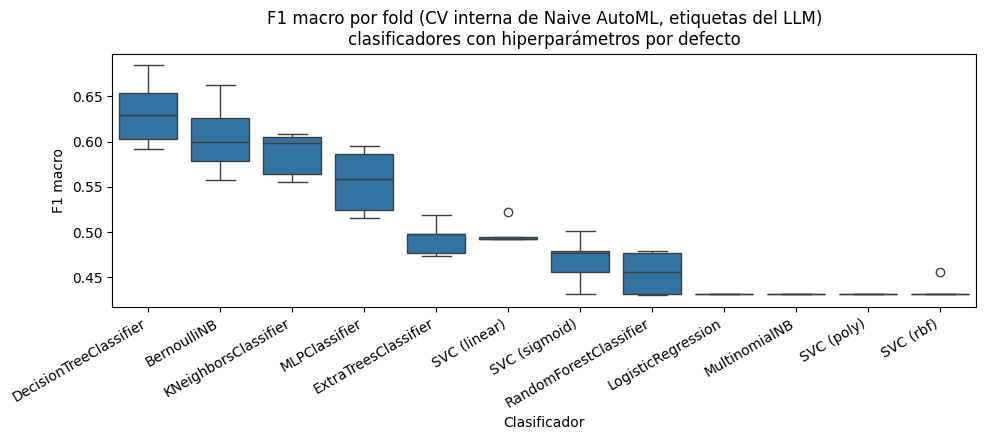

In [42]:
import re, ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

hist = naml.history.copy()
hist = hist[hist["status"] == "ok"]

# Solo clasificadores con hiperparámetros por defecto y sin preprocesadores
base = hist[(hist["default_hp"] == True)
            & hist["data-pre-processor_class"].isna()
            & hist["feature-pre-processor_class"].isna()]

def nombre_modelo(r):
    n = r["learner_class"].split(".")[-1]
    if n == "SVC":                                   # separar SVC por kernel
        k = re.search(r"kernel='(\w+)'", str(r["pipeline"]))
        n += f" ({k.group(1) if k else 'rbf'})"
    return n

largo = [{"Clasificador": nombre_modelo(r), "F1 macro": f}
         for _, r in base.iterrows()
         for f in (ast.literal_eval(r["evaluation_report"]) if isinstance(r["evaluation_report"], str)
                   else r["evaluation_report"])["f1_macro"]]

df_box = pd.DataFrame(largo)
orden = df_box.groupby("Clasificador")["F1 macro"].median().sort_values(ascending=False).index

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=df_box, x="Clasificador", y="F1 macro", order=orden)
plt.xticks(rotation=30, ha="right")
plt.title("F1 macro por fold (CV interna de Naive AutoML, etiquetas del LLM)\n"
          "clasificadores con hiperparámetros por defecto")
plt.tight_layout()
plt.savefig("boxplot_clasificadores.png", dpi=200, bbox_inches="tight")
plt.show()

In [43]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier

def crear_pipeline():
    """Modelo final (Diagnóstico): TF-IDF con números (1-3 gramas, min_df=3) + árbol de decisión (elegido por el AutoML)."""
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 3), min_df=3)),
        ("dt",    DecisionTreeClassifier(random_state=42)),
    ])

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, roc_auc_score, RocCurveDisplay,
                             ConfusionMatrixDisplay, confusion_matrix)

Xtr, Xva, Xte = X_train.fillna(""), X_val.fillna(""), X_test.fillna("")

# Modelo final: SOLO train (etiquetas LLM)
final = crear_pipeline().fit(Xtr, y_train)

¿Más datos mejorarían el modelo? ¿Memoriza?

AUC val: 0.689 | AUC test: 0.740


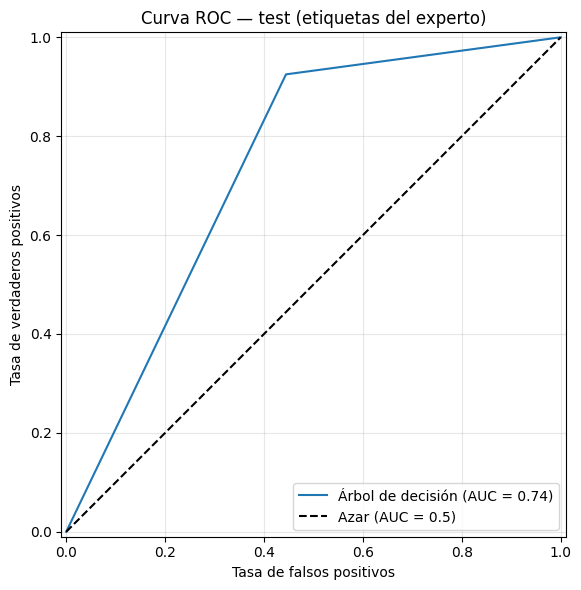

In [57]:
score_te = final.predict_proba(Xte)[:, 1]  
auc_te = roc_auc_score(y_test, score_te)
auc_va = roc_auc_score(y_val, final.predict_proba(Xva)[:, 1])
print(f"AUC val: {auc_va:.3f} | AUC test: {auc_te:.3f}")

fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_test, score_te, ax=ax, name="Árbol de decisión")   # el AUC lo agrega solo
ax.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
ax.set(title="Curva ROC — test (etiquetas del experto)",
       xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("curva_roc_test.png", dpi=200, bbox_inches="tight"); plt.show()

Revolver el df val y df test


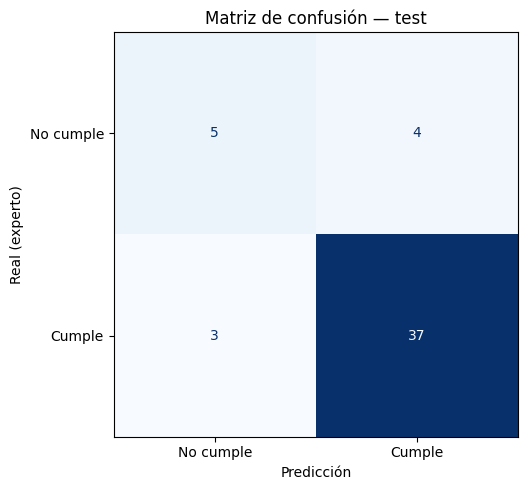

In [49]:
pred_te = final.predict(Xte)

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_te, labels=[0, 1]),
                       display_labels=["No cumple", "Cumple"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set(title="Matriz de confusión — test", xlabel="Predicción", ylabel="Real (experto)")
plt.tight_layout(); plt.savefig("matriz_confusion_test.png", dpi=200, bbox_inches="tight"); plt.show()

In [55]:
from sklearn.metrics import classification_report, f1_score

pred_val  = final.predict(Xva)
pred_test = final.predict(Xte)

print("F1 macro val  (experto):", round(f1_score(y_val,  pred_val,  average="macro"), 3))
print("F1 macro test (experto):", round(f1_score(y_test, pred_test, average="macro"), 3))
print()
print(classification_report(y_test, pred_test, digits=3,
                            target_names=["No cumple (0)", "Cumple (1)"]))

F1 macro val  (experto): 0.68
F1 macro test (experto): 0.751

               precision    recall  f1-score   support

No cumple (0)      0.625     0.556     0.588         9
   Cumple (1)      0.902     0.925     0.914        40

     accuracy                          0.857        49
    macro avg      0.764     0.740     0.751        49
 weighted avg      0.851     0.857     0.854        49



In [52]:
naml_modelo    = naml.chosen_model 
naml_modelo

Pipeline(steps=[('impute_and_binarize',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                   10, 11, 12, 13, 14, 15, 16,
                                                   17, 18, 19, 20, 21, 22, 23,
                                                   24, 25, 26, 27, 28, 29, ...]),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('binarizer',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [])])),
                ('learner', DecisionTreeClassifier())])

## Conclusiones — Criterio Diagnóstico

### 1. Datos

- **Entrenamiento:** 899 notas etiquetadas por el LLM (few-shot).
- **Validación y test:** 98 notas etiquetadas por el experto (81 cumple / 17 no cumple), divididas de forma estratificada en validación (41 / 8) y test (40 / 9).
- Ninguna nota del experto se usó para entrenar.

### 2. Tokenización y representación

Se compararon 3 tokenizaciones × 4 representaciones con regresión logística (validación cruzada anidada sobre las 98 notas del experto):

| Representación | Sin números | Con números | Número genérico |
|---|---|---|---|
| BoW | 0.583 | 0.583 | 0.583 |
| TF-IDF | 0.569 | **0.589** | 0.560 |
| W2V | 0.521 | 0.401 | 0.451 |
| W2V + TF-IDF | 0.540 | 0.593 | **0.610** |

*F1 macro promedio entre folds.*

- La combinación con mayor F1 macro fue **W2V + TF-IDF con número genérico (0.610)**, pero con una desviación alta (± 0.216) y un recall de "No cumple" bajo (0.233).
- Se eligió **TF-IDF con números** porque obtuvo el mayor recall de "No cumple" (0.300) con menor variabilidad y una representación más simple. En auditoría es prioritario detectar los incumplimientos.
- Las diferencias entre combinaciones (≈ 0.02–0.05) son menores que la desviación entre folds (0.13–0.22), por lo que no son estadísticamente concluyentes.
- Igual que en el examen físico, **W2V empeora al conservar los números** (0.521 → 0.401), porque con pocas notas por fold no aprende buenos vectores para valores numéricos poco frecuentes.

Representación final: **TF-IDF con números, de 1 a 3 gramas, `min_df=3`** (33 164 dimensiones).

### 3. Selección del clasificador (Naive AutoML)

- El AutoML completó la selección de algoritmos (32/32) y el ajuste de hiperparámetros (20 iteraciones), usando validación cruzada sobre las etiquetas del LLM.
- El mejor fue un **árbol de decisión** (mediana de F1 ≈ 0.63), seguido de BernoulliNB (≈ 0.60) y KNN (≈ 0.59).
- Varios modelos (regresión logística, MultinomialNB, SVC rbf/poly) quedaron en F1 ≈ 0.43, lo que equivale a predecir siempre "Cumple": sin balanceo de clases no logran aprender la clase minoritaria.
- En general, el F1 interno fue más bajo que en el criterio Examen físico (máximo ≈ 0.65 frente a ≈ 0.78), lo que indica que las etiquetas del LLM para Diagnóstico son más difíciles de aprender a partir del texto.

**Regularización del árbol.** Se probó limitar el árbol (`max_depth=10`, `min_samples_leaf=20`, elegidos por validación cruzada sobre train):

| Árbol | F1 entrenamiento | F1 validación | Recall "No cumple" val |
|---|---|---|---|
| Sin límites (AutoML) | 1.000 | **0.680** | **0.500** |
| Regularizado | 0.769 | 0.552 | 0.250 |

La regularización reduce el sobreajuste, pero impide aprender patrones de la clase minoritaria y empeora el desempeño frente al experto. **Se mantuvo el árbol sin restricciones**, con `random_state=42` para que sea reproducible.

### 4. Curva de aprendizaje

- El F1 de entrenamiento es 1.0 en todos los tamaños: el árbol memoriza las notas de entrenamiento.
- El F1 de validación sube de ≈ 0.56 (180 notas) a ≈ 0.68 (899 notas) y no se estabiliza. **Más notas etiquetadas por el LLM probablemente mejorarían el modelo.**

### 5. Resultado final

Modelo final: **TF-IDF con números (1-3 gramas, `min_df=3`) + árbol de decisión**, entrenado con las 899 notas del LLM.

| Clase | Precisión | Recall | F1 | Notas |
|---|---|---|---|---|
| No cumple (0) | 0.625 | 0.556 | 0.588 | 9 |
| Cumple (1) | 0.902 | 0.925 | 0.914 | 40 |
| **Macro** | **0.764** | **0.740** | **0.751** | 49 |

*Test, etiquetas del experto.*

| Métrica | Validación | Test |
|---|---|---|
| F1 macro | 0.680 | 0.751 |
| AUC | 0.689 | 0.740 |
| Accuracy | — | 0.857 |

- En test, el modelo detecta **5 de las 9 notas que no cumplen** y clasifica correctamente **37 de las 40 que cumplen**.
- El AUC es moderado porque un árbol de decisión asigna probabilidades casi siempre de 0 o 1. Para este modelo, la matriz de confusión es más informativa que la curva ROC.
- El test superó a la validación (0.751 frente a 0.680). Con solo 8–9 notas "No cumple" por conjunto, una o dos notas cambian sensiblemente el F1 macro, por lo que la diferencia se atribuye a la variabilidad de muestras pequeñas.

### 6. Comparación con el criterio Examen físico

| Criterio | Modelo | F1 val | F1 test | "No cumple" detectados (test) |
|---|---|---|---|---|
| Examen físico | TF-IDF (1-3) + BernoulliNB | 0.864 | 0.728 | 5 de 9 |
| Diagnóstico | TF-IDF (1-3) + Árbol de decisión | 0.680 | 0.751 | 5 de 9 |

- Cada criterio quedó con un clasificador distinto, coherente con que cada uno depende de partes diferentes de la nota clínica.
- Ambos modelos detectan aproximadamente la mitad de los incumplimientos. Son útiles como **filtro inicial** para priorizar la revisión, pero no reemplazan la revisión de un auditor.

### 7. Limitaciones y trabajo futuro

- **Muestra pequeña del experto:** 98 notas, con solo 17 "No cumple", hacen que las métricas tengan alta variabilidad.
- **Dependencia de las etiquetas del LLM:** el modelo aprende a imitar al LLM. Medir el acuerdo entre el LLM y el experto permitiría estimar el techo de desempeño y mejorar el prompt de etiquetado.
- **Más datos:** la curva de aprendizaje sugiere que más notas etiquetadas por el LLM mejorarían el modelo.
- **Representaciones:** probar embeddings preentrenados (por ejemplo, modelos multilingües o clínicos en español) en lugar de TF-IDF.
- **Enfoque en la sección relevante:** usar solo la parte de la nota donde se documenta el diagnóstico podría reducir el ruido.

In [53]:
### guarda en caso de caida del kernel

import os, types, dill

def guardar_sesion(ruta='resultados/sesion.pkl'):
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    datos, omitidas = {}, []
    for nombre, valor in list(globals().items()):
        # saltar variables internas, módulos y cosas de Jupyter
        if nombre.startswith('_') or isinstance(valor, types.ModuleType) \
           or nombre in ('In', 'Out', 'exit', 'quit', 'get_ipython'):
            continue
        try:
            dill.dumps(valor)      # prueba si se puede guardar
            datos[nombre] = valor
        except Exception:
            omitidas.append(nombre)
    with open(ruta, 'wb') as f:
        dill.dump(datos, f)
    print(f'Guardadas {len(datos)} variables.')
    if omitidas:
        print('No se pudieron guardar:', omitidas)


guardar_sesion()

Guardadas 160 variables.
No se pudieron guardar: ['naml']


In [2]:
### Carga en caso de caida del kernel

import dill

def cargar_sesion(ruta='resultados/sesion.pkl'):
    with open(ruta, 'rb') as f:
        globals().update(dill.load(f))
    print('Sesión restaurada.')

cargar_sesion()

Sesión restaurada.
